# LLM 微调：让小型代码模型形成稳定的输出习惯

**先修阅读：** [前置知识](前置知识.md)。先建立模型与数据的整体图景，再逐节运行本练习。

本例选择代码风格：将当前项目中的 pandas/NumPy 操作整理成“需求 → 期望代码”，用 **SFT + LoRA** 微调公开的 Qwen2.5-Coder-0.5B-Instruct。

目标是无需每次重复“只给简洁函数、避免无用说明、使用数组/表格操作”，模型也更倾向这种答案。推理时仍需要具体需求和必要的运行上下文。

这里是项目约定的一个可测量子集，不代表 32 条样例就能学会你的全部代码风格或复杂架构判断。课程代码中也有参考答案和后续修正；数据文件明确标为人工整理的教学改写，而非你的原始代码全集。

## 1. 为什么先选代码风格

| 目标 | 更合适的第一步 |
|---|---|
| 固定的表达、格式、常见代码取向 | 用审核过的需求/答案对做 SFT |
| 当前代码库有哪些文件、接口和最新实现 | 检索或提供当前文件上下文 |
| 最新法律条文、出处和适用时间 | 检索权威资料，保留引用 |
| 法律论证方式或设计判断 | 审核过的问题/论证或问题/方案样例，配合专业评估 |

把原始法条或代码文件用于下一 token 训练，属于一种领域适应思路；它与“看到需求就按习惯回答”的监督微调有不同的数据形式。小规模训练损失下降不能证明法律推理可靠，也不能证明大型软件设计能力提升。

本例本地训练，不上传样例到模型平台。首次只下载公开模型；训练数据是仓库中的 style_examples.jsonl。

## 2. 运行设置

先按同目录 README 安装独立环境，选择 Python 内核。已在 Apple Silicon Mac 上准备环境；MPS 可用时使用它，否则使用 CPU。CPU 也能运行，但训练与生成可能明显变慢。

使用约 0.49B 参数的代码模型，首次权重下载约 1 GB。它已经具有编程基础；我们不假设它原本不懂 pandas，更不把本次微调当作从零学编程。固定模型 revision，便于复现。

默认 4 个 epoch、batch size=2、LoRA rank=8、学习率 0.0005，都是教学实验设置；用验证集决定保留哪一轮。

In [1]:
# 准备环境：设置模型缓存、训练参数、随机种子，以及 MPS 或 CPU 计算设备。
import hashlib
import json
import os
import platform
import random
import sys
from functools import partial
from pathlib import Path
from time import perf_counter

# 定位示例目录，让本地 lesson_utils 可导入，并将公开模型缓存放在示例目录下。
EXAMPLE_DIR = Path("扩展练习/LLM代码风格微调")
if not EXAMPLE_DIR.is_dir():
    EXAMPLE_DIR = Path(".")
sys.path.insert(0, str(EXAMPLE_DIR))
os.environ.setdefault("HF_HOME", str(EXAMPLE_DIR / ".cache" / "huggingface"))
os.environ.setdefault("HF_HUB_DISABLE_TELEMETRY", "1")

import matplotlib.pyplot as plt
import numpy as np
import torch
import transformers
import peft
from peft import (
    LoraConfig, PeftModel, get_peft_model,
    get_peft_model_state_dict, set_peft_model_state_dict,
)
from torch.utils.data import DataLoader
from transformers import AutoModelForCausalLM, AutoTokenizer, GenerationConfig
from lesson_utils import read_examples, encode_example, collate_batch, style_checks

# MAX_LENGTH 限制训练序列总长；MAX_NEW_TOKENS 单独限制推理时新生成的长度。
SEED = 42
EPOCHS = 4
BATCH_SIZE = 2
LEARNING_RATE = 5e-4
MAX_LENGTH = 256
MAX_NEW_TOKENS = 512
MODEL_ID = "Qwen/Qwen2.5-Coder-0.5B-Instruct"
MODEL_REVISION = "ea3f2471cf1b1f0db85067f1ef93848e38e88c25"

# 固定随机种子便于比较；MPS 可用时使用 Mac GPU，否则使用 CPU。
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
CACHE_DIR = EXAMPLE_DIR / ".cache" / "huggingface" / "hub"
OUTPUT_DIR = EXAMPLE_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", platform.python_version(), "Architecture:", platform.machine())
print("PyTorch:", torch.__version__, "Transformers:", transformers.__version__)
print("PEFT:", peft.__version__, "Device:", device)


Python: 3.12.14 Architecture: arm64
PyTorch: 2.10.0 Transformers: 4.57.6
PEFT: 0.18.1 Device: mps


## 3. 训练材料是需求与答案，不是随意拼接所有代码

样例来自课程中已经讨论过的过滤、缺失统计、分组、编码和 NumPy 处理。每条有 source_refs，标明参考的操作来源；函数包装和需求文本是为教学编写的。

24 条训练样例、4 条验证样例、4 条测试样例提前固定。同一逻辑任务不会以换函数名/换问法的形式跨集合复制；这里仍是同一个 pandas/NumPy 小领域，不能当作完全陌生软件任务的强泛化测试。

prompt 给出函数名、功能和已导入 pd/np 的运行背景，没有附加输出风格规则。response 则一致采用简洁的 Python 函数。数据质量决定模型被鼓励形成什么习惯。

In [2]:
# 读取监督样例：每条记录包含需求和期望答案，按预先标记的 split 分组。
examples_path = EXAMPLE_DIR / "style_examples.jsonl"
examples = read_examples(examples_path)
# 字典推导式为 train、validation、test 分别筛出样例，不在这里重新随机划分。
splits = {
    split: [row for row in examples if row["split"] == split]
    for split in ["train", "validation", "test"]
}
# 用任务编号集合检查交集，防止同一逻辑任务跨集合造成评估泄漏。
task_sets = {split: {row["task_id"] for row in rows} for split, rows in splits.items()}
assert task_sets["train"].isdisjoint(task_sets["validation"])
assert task_sets["train"].isdisjoint(task_sets["test"])
assert task_sets["validation"].isdisjoint(task_sets["test"])

# 展示一条训练需求、目标代码及来源，确认实际教给模型的内容。
print("Samples:", {split: len(rows) for split, rows in splits.items()})
print("Training prompt:\n", splits["train"][0]["prompt"])
print("Desired answer:\n", splits["train"][0]["response"])
print("Provenance:", splits["train"][0]["provenance"])


Samples: {'train': 24, 'validation': 4, 'test': 4}
Training prompt:
 已导入 pandas as pd 和 numpy as np。编写 filter_sensor_types(data, allowed_types)，筛选 SensorType 属于给定列表的行，返回独立副本。
Desired answer:
 def filter_sensor_types(data, allowed_types):
    return data.loc[data["SensorType"].isin(allowed_types)].copy()

Provenance: teaching adaptation of a repository operation; prompt and function wrapper authored for this lesson


## 4. token、聊天模板和训练标签

Tokenizer 将文本变成 token 编号，token 不一定等于一个词或一个汉字。聊天模板提供 user/assistant 等边界；它是模型的输入格式，不是本例额外注入的风格指令。

SFT 用需求作条件，学习输出期望答案。我们只对 assistant 答案和结束 token 计算损失：

| 位置 | input_ids | labels |
|---|---|---|
| user 需求与 assistant 开始标记 | 对应 token 编号 | -100，忽略损失 |
| assistant 答案 | 对应 token 编号 | 答案 token 编号 |
| 真正的回答结束 token | EOS 编号 | EOS 编号，仍要学习 |
| batch 补齐位置 | PAD 编号 | -100 |

即使 PAD 与 EOS 使用同一编号，也要按位置区分它们。模型内部处理“预测下一 token”的一位移位，不需要再手工把 labels 移位。超长样例直接报错，避免把半段代码当作完整答案。

可在 lesson_utils.py 查看这些步骤；test_lesson.py 专门检查了答案遮罩与 EOS/PAD 的边界。

In [3]:
# 编码与组批：将需求/答案转成 token 张量，只让答案位置参与监督损失。
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID, revision=MODEL_REVISION, cache_dir=str(CACHE_DIR), token=False
)
# 允许用 EOS 编号补齐，但补齐位置的 labels 仍须设为 -100，不能当成真实答案。
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

# encode_example 应用聊天模板；需求和补齐位置不计损失，答案和真正结束标记计损失。
encoded = {
    split: [encode_example(tokenizer, row, MAX_LENGTH) for row in rows]
    for split, rows in splits.items()
}
# DataLoader 负责分批；partial 预先传入 PAD 编号，collate_batch 将批内序列补成相同长度。
loaders = {
    split: DataLoader(
        rows, batch_size=BATCH_SIZE, shuffle=(split == "train"),
        collate_fn=partial(collate_batch, pad_token_id=tokenizer.pad_token_id),
        generator=torch.Generator().manual_seed(SEED),
        num_workers=0,
    )
    for split, rows in encoded.items()
}
# 通过布尔筛选只解码有效监督标签，直观看到哪些 token 会影响训练。
sample = encoded["train"][0]
target_ids = sample["labels"][sample["labels"] != -100]
print("Longest sequence:", max(len(row["input_ids"]) for rows in encoded.values() for row in rows))
print("Only these tokens contribute to loss:\n", tokenizer.decode(target_ids))
batch = next(iter(loaders["train"]))
print("input_ids / labels:", batch["input_ids"].shape, batch["labels"].shape)
# attention_mask 为 0 的位置是补齐位置；检查它们全部被损失函数忽略。
assert torch.all(batch["labels"][batch["attention_mask"] == 0] == -100)


Longest sequence: 102
Only these tokens contribute to loss:
 def filter_sensor_types(data, allowed_types):
    return data.loc[data["SensorType"].isin(allowed_types)].copy()
<|im_end|>
input_ids / labels: torch.Size([2, 71]) torch.Size([2, 71])


## 5. LoRA 与 SFT 是两个不同维度

SFT 决定“用什么监督目标训练”；LoRA 决定“更新哪一小部分参数”。

LoRA 冻结原有矩阵，训练低秩增量。简化表示为：

$$
W = W_0 + \frac{\alpha}{r}BA
$$

本例只在注意力层的 q_proj、v_proj 添加 rank=8 的适配器。它与上一题解冻 layer4 不同：原有基础权重保持固定，学习的是附加参数。它也不是检索系统。

LLM 的 logits 形状是 (batch, token_length, vocabulary_size)，每个位置预测下一个 token；不像图像分类每张图只输出一组类别得分。

In [4]:
# 构建 LoRA：加载固定版本基础模型，只在注意力的 q_proj/v_proj 添加可训练增量。
base = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, revision=MODEL_REVISION, cache_dir=str(CACHE_DIR),
    dtype=torch.float32, attn_implementation="sdpa",
    use_safetensors=True, token=False,
)
# 训练时关闭生成用的 KV 缓存；训练关注整段序列的损失。
base.config.use_cache = False
# r 是低秩维度；alpha 控制增量缩放，dropout 在训练时随机丢弃部分适配器输入。
config = LoraConfig(
    r=8, lora_alpha=16, lora_dropout=0.05,
    target_modules=["q_proj", "v_proj"],
    bias="none", task_type="CAUSAL_LM",
    revision=MODEL_REVISION,
)
model = get_peft_model(base, config).to(device)
model.print_trainable_parameters()
# 检查可训练参数的名称，确认基础模型参数没有被意外放开训练。
only_lora_trainable = all(
    "lora_" in name for name, parameter in model.named_parameters()
    if parameter.requires_grad
)
assert only_lora_trainable

# 选取一块被冻结的基础权重留作对照，后面检查它是否保持原值。
frozen_name, frozen_parameter = next(
    (name, parameter) for name, parameter in model.named_parameters()
    if name.endswith("q_proj.base_layer.weight")
)
frozen_before = frozen_parameter.detach().cpu().clone()

# 仅复制 LoRA 状态到 CPU；本例未训练 embedding，因此不额外保存 embedding 层。
def adapter_state():
    return {
        name: tensor.detach().cpu().clone()
        for name, tensor in get_peft_model_state_dict(model, save_embedding_layers=False).items()
    }

initial_adapter = adapter_state()
print("Frozen weight watched:", frozen_name)


trainable params: 540,672 || all params: 494,573,440 || trainable%: 0.1093
Frozen weight watched: base_model.model.model.layers.0.self_attn.q_proj.base_layer.weight


## 6. 先测基础模型，再训练

这里的 loss 是答案 token 的平均负对数似然：模型给参考答案分配的概率越高，loss 越低。它不等于代码正确率，也不是法律事实准确率。

验证集用于选择 epoch；测试样例只在选择完成后比较基础模型与适配器模型。训练时的梯度计算与上一题相同：zero_grad → forward/loss → backward → step。

In [5]:
# 训练与选优：先测基础验证损失，再训练 LoRA，并恢复验证损失最低的适配器。
# 评估时关闭梯度；按有效答案 token 数加权，避免短批次与长批次权重相同。
def token_loss(loader):
    model.eval()
    loss_sum = 0.0
    token_count = 0
    with torch.inference_mode():
        for batch in loader:
            batch = {name: tensor.to(device) for name, tensor in batch.items()}
            output = model(**batch)
            # 模型预测下一 token：首个标签没有前一位置可预测，因此统计 labels[:, 1:] 中非 -100 的位置。
            count = (batch["labels"][:, 1:] != -100).sum().item()
            loss_sum += output.loss.item() * count
            token_count += count
    return loss_sum / token_count

# 将未训练适配器也作为候选；如果训练后都更差，就保留原始适配器状态。
baseline_val_loss = token_loss(loaders["validation"])
best_val_loss = baseline_val_loss
best_epoch = 0
best_adapter = initial_adapter
history = []
# 优化器仅接收 requires_grad=True 的参数，本例就是 LoRA 参数。
optimizer = torch.optim.AdamW(
    [parameter for parameter in model.parameters() if parameter.requires_grad],
    lr=LEARNING_RATE,
)

start_training = perf_counter()
for epoch in range(1, EPOCHS + 1):
    start = perf_counter()
    model.train()
    loss_sum = 0.0
    token_count = 0
    for batch in loaders["train"]:
        batch = {name: tensor.to(device) for name, tensor in batch.items()}
        # 每批依次清除旧梯度、前向求损失、反向求梯度，再更新参数。
        optimizer.zero_grad(set_to_none=True)
        output = model(**batch)
        output.loss.backward()
        # 限制梯度总范数，降低过大更新使训练不稳定的风险；它不会保证收敛。
        torch.nn.utils.clip_grad_norm_(
            [p for p in model.parameters() if p.requires_grad], max_norm=1.0
        )
        optimizer.step()
        count = (batch["labels"][:, 1:] != -100).sum().item()
        loss_sum += output.loss.item() * count
        token_count += count

    train_loss = loss_sum / token_count
    val_loss = token_loss(loaders["validation"])
    history.append({
        "epoch": epoch, "train_loss": train_loss, "val_loss": val_loss,
        "seconds": perf_counter() - start,
    })
    print(
        f"Epoch {epoch}/{EPOCHS} | train NLL={train_loss:.4f} "
        f"val NLL={val_loss:.4f} | {history[-1]['seconds']:.1f}s",
        flush=True,
    )
    # 每轮用验证集决定是否保存快照；不使用测试集挑选轮次。
    if val_loss < best_val_loss:
        best_val_loss, best_epoch = val_loss, epoch
        best_adapter = adapter_state()

training_seconds = perf_counter() - start_training
trained_adapter = adapter_state()
# 检查适配器确实更新，并检查选取的基础权重未变；最后恢复最佳适配器。
parameter_checks = {
    "only_lora_trainable": only_lora_trainable,
    "base_query_weight_unchanged": torch.equal(
        frozen_before, frozen_parameter.detach().cpu()
    ),
    "adapter_updated_during_training": any(
        not torch.equal(initial_adapter[name], tensor)
        for name, tensor in trained_adapter.items()
    ),
}
assert all(parameter_checks.values())
set_peft_model_state_dict(model, best_adapter)
print("Parameter checks:", parameter_checks)
print("Base validation NLL:", baseline_val_loss)
print("Selected epoch:", best_epoch, "Validation NLL:", best_val_loss)


Epoch 1/4 | train NLL=0.6046 val NLL=0.1868 | 4.7s


Epoch 2/4 | train NLL=0.1288 val NLL=0.1513 | 1.4s


Epoch 3/4 | train NLL=0.0278 val NLL=0.1356 | 1.7s


Epoch 4/4 | train NLL=0.0086 val NLL=0.1526 | 1.4s


Parameter checks: {'only_lora_trainable': True, 'base_query_weight_unchanged': True, 'adapter_updated_during_training': True}
Base validation NLL: 1.4849207060677665
Selected epoch: 3 Validation NLL: 0.13558495683329447


## 7. 相同需求、相同生成设置，比较微调前后

使用 disable_adapter() 临时关闭 LoRA，就是未经本次微调的基础模型；基础权重已检查没有变化。两个版本都只看到相同的 user 需求及模型聊天模板，没有附带风格规则、训练例或 few-shot 示例。

静态检查把“能否直接解析原始答案”与“代码块里的结构”分开；Markdown 包装和代码逻辑是不同问题。无显式循环、函数较短也不能证明功能正确或设计合理。本例不自动执行模型生成的代码。

每段输出都记录是否碰到生成长度上限。若基础答案被截断，要把它视为本次长度预算下的结果，不据此断言模型完全不会该任务。

In [6]:
# 比较微调前后：对相同测试需求使用相同生成设置，并统计输出习惯与参考答案损失。
# do_sample=False 使用贪心生成，减少随机采样对前后比较的干扰。
generation_config = GenerationConfig(
    max_new_tokens=MAX_NEW_TOKENS, do_sample=False, use_cache=True,
    pad_token_id=tokenizer.pad_token_id, eos_token_id=tokenizer.eos_token_id,
)

# 先套用基础模型的聊天模板，再逐 token 生成回答。
def generate_answer(current_model, current_tokenizer, prompt):
    input_ids = current_tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt}],
        tokenize=True, add_generation_prompt=True, return_tensors="pt",
    ).to(device)
    current_model.eval()
    with torch.inference_mode():
        # generate 返回提示词加新回答；[0, 提示词长度:] 取第一条序列的新回答部分。
        output_ids = current_model.generate(
            input_ids=input_ids, attention_mask=torch.ones_like(input_ids),
            generation_config=generation_config,
        )[0, input_ids.shape[1]:]
    return {
        "response": current_tokenizer.decode(output_ids, skip_special_tokens=True),
        "generated_tokens": len(output_ids),
        "hit_token_limit": (
            len(output_ids) >= MAX_NEW_TOKENS
            and int(output_ids[-1]) != current_tokenizer.eos_token_id
        ),
    }

# 临时关闭 LoRA 得到基础模型结果；离开 with 后恢复适配器，使用同样需求比较。
with model.disable_adapter():
    baseline_test_loss = token_loss(loaders["test"])
    before = [generate_answer(model, tokenizer, row["prompt"]) for row in splits["test"]]
after_test_loss = token_loss(loaders["test"])
after = [generate_answer(model, tokenizer, row["prompt"]) for row in splits["test"]]

# 逐题保留完整前后输出；风格静态检查不能证明生成代码的功能正确。
comparisons = []
for row, original, tuned in zip(splits["test"], before, after):
    original["style"] = style_checks(original["response"], row["function_name"])
    tuned["style"] = style_checks(tuned["response"], row["function_name"])
    comparisons.append({
        "task_id": row["task_id"], "prompt": row["prompt"],
        "before": original, "after": tuned,
    })
    print("\nTASK:", row["task_id"])
    print("BEFORE:\n", original["response"])
    print("AFTER:\n", tuned["response"])
    print("Style:", original["style"], "->", tuned["style"])

# 检查结果是布尔值，sum 将 True 按 1 累加，得到各项风格通过的题数。
style_totals = {
    version: {
        metric: sum(item[version]["style"][metric] for item in comparisons)
        for metric in comparisons[0][version]["style"]
    }
    for version in ["before", "after"]
}
print("\nStyle counts out of", len(comparisons), ":", style_totals)
# 单独统计触及长度上限的回答，避免把截断输出误认为完整回答。
generation_limit_counts = {
    version: sum(item[version]["hit_token_limit"] for item in comparisons)
    for version in ["before", "after"]
}
print("Reached generation limit:", generation_limit_counts)
print("Test reference-answer NLL:", baseline_test_loss, "->", after_test_loss)



TASK: filter_range
BEFORE:
  要编写一个函数 `filter_range`，它根据给定数值列筛选闭区间内的行，并返回独立副本，可以使用 `pandas` 库。以下是一个示例实现：

```python
import pandas as pd
import numpy as np

def filter_range(data, column, lower, upper):
    """
    根据给定数值列筛选闭区间内的行，并返回独立副本。

    参数:
    - data: pandas DataFrame，包含数据。
    - column: 字符串，表示要筛选的数值列。
    - lower: 数字，表示闭区间内的下限。
    - upper: 数字，表示闭区间内的上限。

    返回:
    - pandas DataFrame，筛选后的数据。
    """
    # 创建一个布尔索引，筛选出符合条件的行
    filtered_data = data[data[column] >= lower] & data[column] <= upper
    
    # 返回独立副本
    return filtered_data.copy()

# 示例数据
data = pd.DataFrame({
    'A': [1, 2, 3, 4, 5],
    'B': [10, 20, 30, 40, 50],
    'C': [100, 200, 300, 400, 500]
})

# 调用函数并打印结果
result = filter_range(data, 'A', 10, 50)
print(result)
```

在这个示例中，`filter_range` 函数接受一个 DataFrame、一个数值列、下限和上限作为参数。它使用布尔索引筛选出符合条件的行，并返回一个独立副本。
AFTER:
 def filter_range(data, column, lower, upper):
    return data.loc[(data[column] >= lower) & (data[column] <= upper)].copy()

Style: {'raw_python': Fal

## 8. 保存适配器，重新加载验证

保存的是 LoRA 增量，不是完整基础模型。推理需要：固定版本的基础模型 + 适配器 + tokenizer/聊天模板。

下面从本地缓存加载同一基础版本，再加载适配器。用 local_files_only=True 验证重载不需要再次请求模型平台。比较 logits，并检查一次贪心生成是否一致。

In [7]:
# 保存与重载：保存 LoRA 增量和 tokenizer，再从本地缓存恢复同版本基础模型验证结果。
# 适配器文件不包含完整基础模型；本例不训练 embedding，所以显式不保存该层。
adapter_dir = OUTPUT_DIR / "adapter"
model.save_pretrained(
    adapter_dir, safe_serialization=True, save_embedding_layers=False
)
tokenizer.save_pretrained(adapter_dir)

# 记录基础模型版本、训练数据哈希和超参数，明确本次结果依赖哪些输入。
manifest = {
    "base_model": MODEL_ID, "base_revision": MODEL_REVISION,
    "dtype": "float32", "seed": SEED,
    "dataset_sha256": hashlib.sha256(examples_path.read_bytes()).hexdigest(),
    "selected_epoch": best_epoch,
    "hyperparameters": {
        "epochs": EPOCHS, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE,
        "max_length": MAX_LENGTH, "max_new_tokens": MAX_NEW_TOKENS,
        "lora_rank": 8, "lora_alpha": 16, "target_modules": ["q_proj", "v_proj"],
    },
    "versions": {
        "python": platform.python_version(), "torch": str(torch.__version__),
        "transformers": transformers.__version__, "peft": peft.__version__,
        "device": device.type,
    },
}
(OUTPUT_DIR / "manifest.json").write_text(
    json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8"
)

# local_files_only=True 禁止重新下载，验证现有缓存足够完成离线重载。
reloaded_tokenizer = AutoTokenizer.from_pretrained(adapter_dir, local_files_only=True)
reloaded_base = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, revision=MODEL_REVISION, cache_dir=str(CACHE_DIR),
    dtype=torch.float32, attn_implementation="sdpa",
    use_safetensors=True, local_files_only=True,
)
reloaded = PeftModel.from_pretrained(reloaded_base, adapter_dir).to(device)
reloaded.eval()
model.eval()

# 对同一个需求检查 tokenizer 编码一致，再检查最后一个 token 位置的词表 logits。
reload_prompt = splits["test"][0]["prompt"]
input_ids = tokenizer.apply_chat_template(
    [{"role": "user", "content": reload_prompt}],
    tokenize=True, add_generation_prompt=True, return_tensors="pt",
).to(device)
reloaded_ids = reloaded_tokenizer.apply_chat_template(
    [{"role": "user", "content": reload_prompt}],
    tokenize=True, add_generation_prompt=True, return_tensors="pt",
).to(device)
assert torch.equal(input_ids, reloaded_ids)
with torch.inference_mode():
    # logits 为 [批次, 序列位置, 词表]；[:, -1, :] 取用于预测下一个 token 的得分。
    original_logits = model(input_ids=input_ids).logits[:, -1, :]
    reloaded_logits = reloaded(input_ids=reloaded_ids).logits[:, -1, :]
    torch.testing.assert_close(original_logits, reloaded_logits, rtol=1e-4, atol=1e-4)
# 除数值得分接近外，再确认贪心生成的整段回答与保存前一致。
reloaded_answer = generate_answer(reloaded, reloaded_tokenizer, reload_prompt)
assert reloaded_answer["response"] == comparisons[0]["after"]["response"]
parameter_checks["offline_reload_matches"] = True
print("Offline reload: tokenizer, logits and generation match")
print("LoRA weight size MiB:", round(
    sum(path.stat().st_size for path in adapter_dir.glob("*.safetensors")) / 1024**2, 2
))


Offline reload: tokenizer, logits and generation match
LoRA weight size MiB: 2.07


## 9. 保留结果和训练曲线

report.json 记录损失、实际权重检查和逐题前后输出；不要把静态风格通过数写成“代码正确率”。训练材料、模型版本和 prompt 都有记录，便于对照。

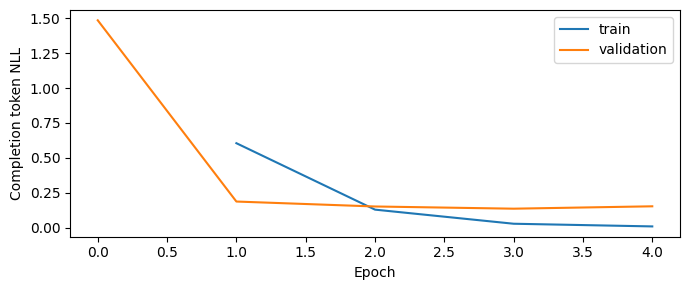

Training seconds: 9.2
Results saved in: outputs


In [8]:
# 保存报告并绘图：汇总训练损失、风格检查、前后回答和耗时，便于回看实验。
report = {
    "manifest": manifest,
    "samples": {split: len(rows) for split, rows in splits.items()},
    "baseline_validation_nll": baseline_val_loss,
    "selected_validation_nll": best_val_loss,
    "test_nll": {"before": baseline_test_loss, "after": after_test_loss},
    "parameter_checks": parameter_checks,
    "style_counts": style_totals,
    "generation_limit_counts": generation_limit_counts,
    "comparisons": comparisons,
    "history": history,
    "training_seconds": training_seconds,
    "evaluation_scope": "small static style checks; not semantic correctness or architecture evaluation",
}
(OUTPUT_DIR / "report.json").write_text(
    json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8"
)

# 验证曲线从 epoch=0 的基础模型开始；损失下降表示更偏好参考答案，不等于代码正确率。
plt.figure(figsize=(7, 3))
plt.plot([row["epoch"] for row in history], [row["train_loss"] for row in history], label="train")
plt.plot([0] + [row["epoch"] for row in history],
         [baseline_val_loss] + [row["val_loss"] for row in history], label="validation")
plt.xlabel("Epoch")
plt.ylabel("Completion token NLL")
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "learning_curve.png", dpi=150)
plt.show()
print("Training seconds:", round(training_seconds, 1))
print("Results saved in:", OUTPUT_DIR)


### 本次保存结果中，风格通过却仍出错的两条答案

- remove_blank_text 仅过滤缺失值，没有过滤空串和纯空白文本。
- get_top_indices 取出最大的 k 项后没有逆序，输出顺序不符合降序要求。

这两条答案都能解析、没有循环、函数也很短。静态风格分数不能替代语义测试。本例保留实际输出，没有根据这些测试答案改变训练数据、学习率或训练轮次。验证集第 3 轮最好，第 4 轮训练损失下降而验证损失回升，正好也能观察过拟合。

本次统一给两个版本 512 个新 token 的生成预算：基础模型仍有一条触及上限，因此结果还受该预算限制。


## 10. 如何扩展到真正的个人代码风格或设计模式

先从稳定、可审查的偏好开始：命名、错误处理、分层接口、数据变换方式和输出形式。原始文件只是候选材料；需要知道代码当时解决的需求，以及哪些实现已经被你认可。

适合的样例是“任务/必要上下文 → 审核通过的实现”，或“坏实现/评审要求 → 修正实现”。不要把过时实现、临时补丁、生成文件、测试夹具或未认可的参考答案当成同等质量的偏好。按逻辑任务、函数/文件、PR 或时间分组划分，避免同一实现的改名版本跨训练与测试。

复杂设计模式需要完整约束和权衡案例，并评估功能测试、接口契约、维护性与通用任务能力。32 条短函数不能证明模型学会了 DDD 或干净架构。当前仓库结构、正在改动的代码和本次需求仍要作为上下文提供。

微调可以减少重复的风格提示，不会消除任务 prompt，也不保证永远遵守约定。法律方向可后续用权威材料构建检索与经审核的论证样例，并采用独立评估；不能通过给模型贴上“不熟悉中国法律”的标签就建立有效对照。

资料：[Qwen 模型卡](https://huggingface.co/Qwen/Qwen2.5-Coder-0.5B-Instruct)、[PEFT LoRA](https://huggingface.co/docs/peft/developer_guides/lora)、[SFT 数据和损失](https://huggingface.co/docs/trl/sft_trainer)。